In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Importing a realistic electron beam

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/09-importing-electron-beams.py)

Inspect correlated positions, angles and energies in a GPT-format beam,
simulate its X-ray spectrum, and ask whether those correlations matter by
comparing it with an ideal pencil beam. The input contains **96 synthetic
weighted records**, not measurements or a GPT simulation.

In [ ]:
import hashlib
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve

import easygdf

# Fetch the input from the release tag matching the installed PyRITE, and verify it.
beam_directory = TemporaryDirectory(prefix="pyrite-gdf-tutorial-")
beam_path = Path(beam_directory.name) / "synthetic_beam.gdf"
_ = urlretrieve(
    "https://raw.githubusercontent.com/Quantum-Light-Matter-Cooperative-QLMC/"
    f"pyrite/v{pyrite.__version__}/docs/examples/data/synthetic_beam.gdf",
    beam_path,
)
expected_sha256 = "d7fc5b72db0d4416a4aff1a188ad7fa3ff4cca269f67cdf863726e35e6a3159a"
assert hashlib.sha256(beam_path.read_bytes()).hexdigest() == expected_sha256
fields = {
    item["name"]: item["value"] for item in easygdf.load(str(beam_path))["blocks"][0]["children"]
}

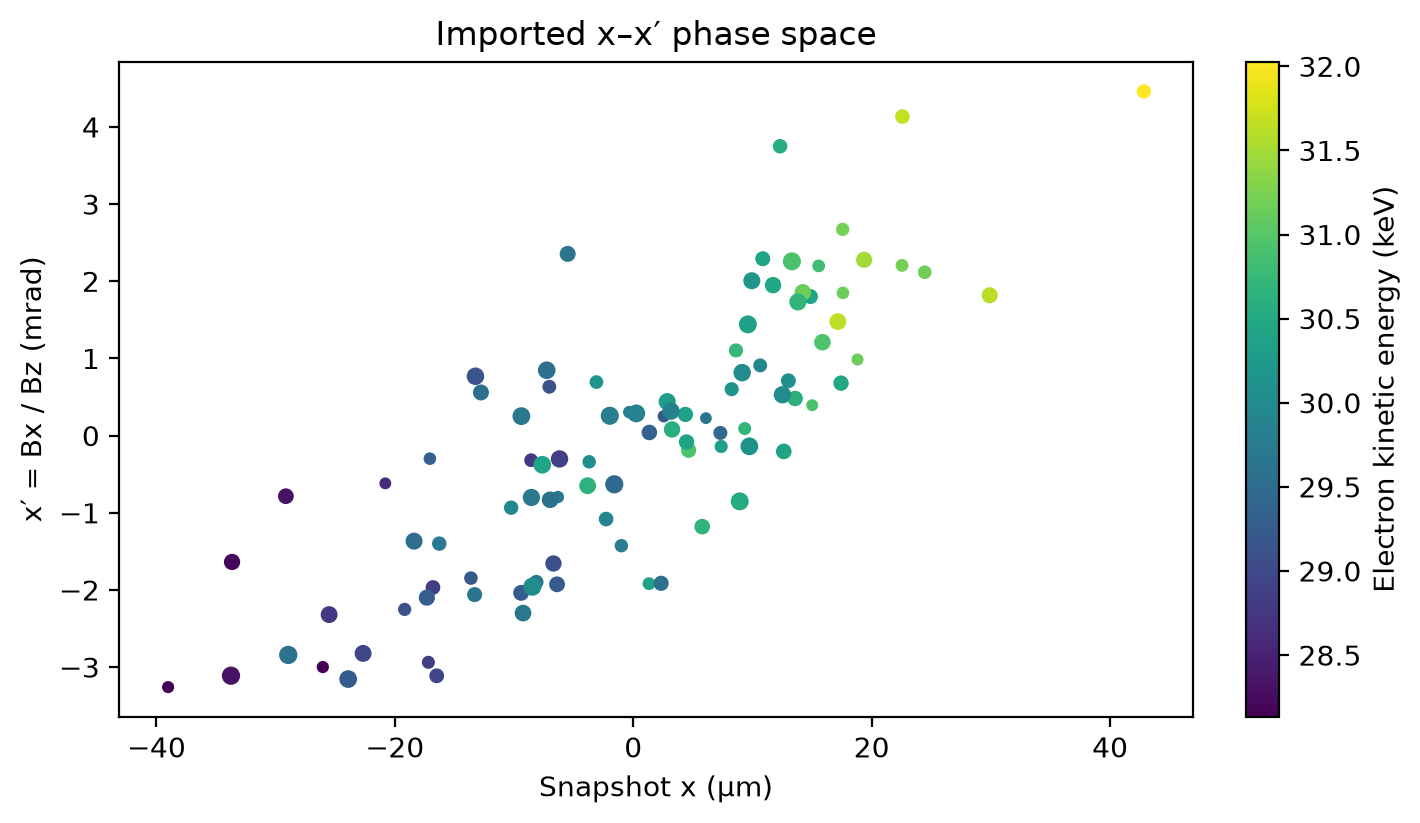

In [ ]:
from scipy.constants import physical_constants

electron_rest_keV = physical_constants["electron mass energy equivalent in MeV"][0] * 1_000
record_weight = fields["nmacro"] / fields["nmacro"].sum()
record_energy_keV = (fields["G"] - 1) * electron_rest_keV
mean_energy_keV = float(np.sum(record_weight * record_energy_keV))

fig_phase, _ax = plt.subplots(figsize=(7, 4), layout="constrained")
_points = _ax.scatter(
    fields["x"] * 1e6,
    fields["Bx"] / fields["Bz"] * 1e3,
    c=record_energy_keV,
    s=2_000 * record_weight,
    cmap="viridis",
)
_ax.set(xlabel="Snapshot x (µm)", ylabel="x′ = Bx / Bz (mrad)", title="Imported x–x′ phase space")
fig_phase.colorbar(_points, ax=_ax, label="Electron kinetic energy (keV)")
fig_phase  # noqa: B018

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab

# Select the 1 ns snapshot and project it relative to lab z = 0.1 m.
imported_beam = Beam.from_gdf(
    str(beam_path),
    time_s=1e-9,
    z_origin_m=0.1,
    energy_keV=30.0,  # scene placeholder; records supply each electron's energy
    normalization="gdf_charge",
    rep_rate_hz=1_000_000.0,
)
# Same mean energy, but no spread, size, divergence or correlation.
pencil_beam = Beam(energy_keV=mean_energy_keV, transverse=PointSpot(), longitudinal=PointBunch())

target = Slab("hopg", thickness_ang=1_000.0, tilt_deg=30.0, footprint=Footprint(1, 1))
detector = Detector(observation_angle_deg=135.0)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=2_048, brem_electrons=2_048),
    cxr_reflections=CxrReflections(n_families=2),
    seed=1,
)
assert tables_ready
spectra = {
    _label: simulate(
        _beam, target, detector, physics=Physics(brem_source="none"), numerics=numerics
    ).cxr.incoherent
    for _label, _beam in (
        ("Imported GDF beam", imported_beam),
        ("Ideal pencil beam", pencil_beam),
    )
}

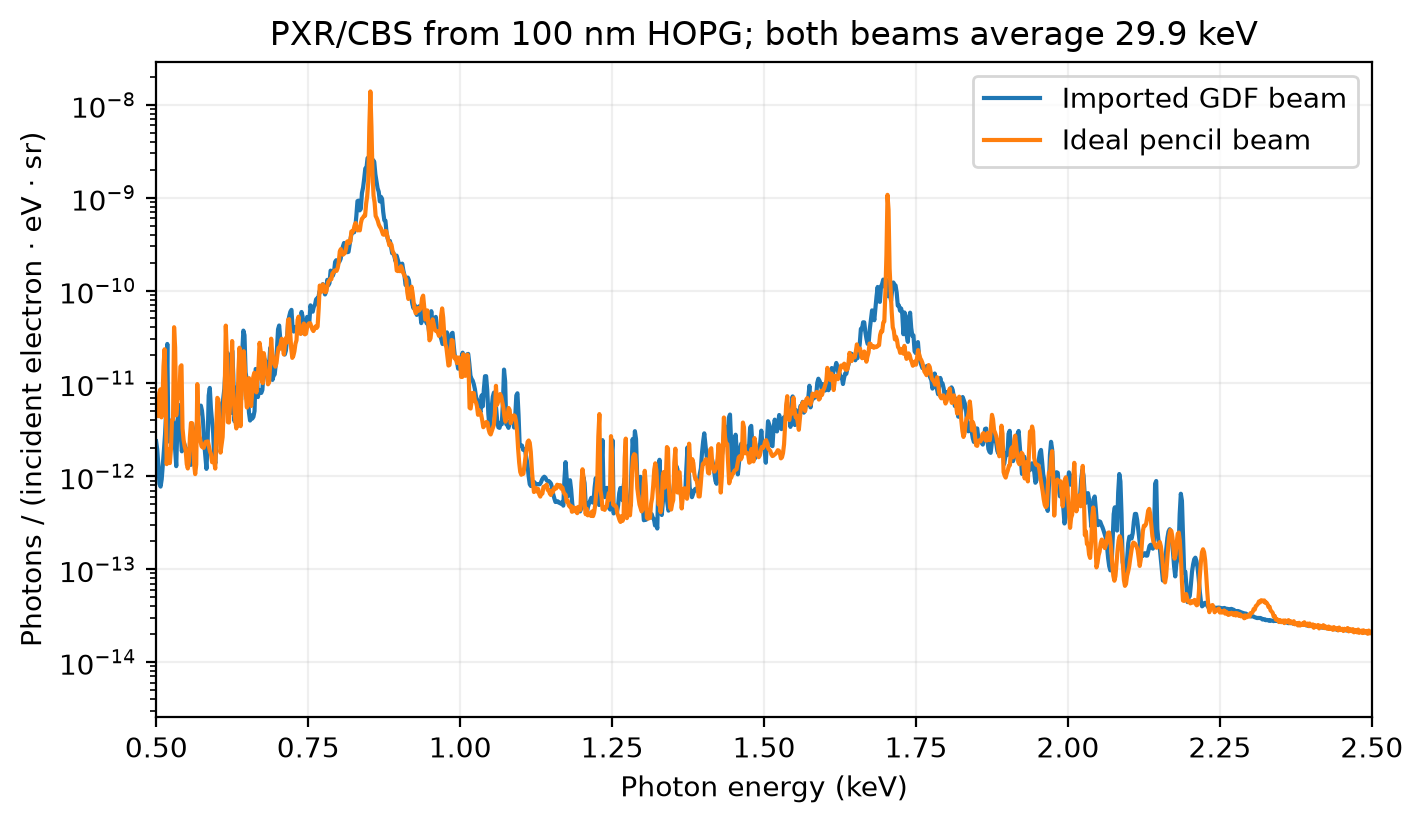

In [ ]:
fig_spectrum, _ax = plt.subplots(figsize=(7, 4), layout="constrained")
for _label, _spectrum in spectra.items():
    _ax.plot(_spectrum.photon_energy_eV / 1_000, _spectrum.density, label=_label)
_ax.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (incident electron · eV · sr)",
    title=f"PXR/CBS from 100 nm HOPG; both beams average {mean_energy_keV:.1f} keV",
    xlim=(0.5, 2.5),
    yscale="log",
)
_ax.grid(alpha=0.2)
_ax.legend()
fig_spectrum  # noqa: B018

In [ ]:
_spread = float(
    np.sqrt(
        np.sum(record_weight * (record_energy_keV - np.sum(record_weight * record_energy_keV)) ** 2)
    )
)
mo.md(f"Weighted RMS kinetic-energy spread of the imported records: **{_spread:.2f} keV**.")

Weighted RMS kinetic-energy spread of the imported records: **0.82 keV**.

## Interpretation

Marker area shows each record's sampling probability. Importing complete
records keeps the position–angle–energy correlations; `Bx`, `By` and `Bz`
are velocities divided by the speed of light. Each line's center depends on
the electron's energy and direction, so the imported beam's energy spread
and divergence smear each line over a range of centers: peaks become lower
and wider than for the ideal pencil beam with the same mean energy, while
the line positions and the broad CBS shoulders barely change. Use the pencil
beam as a quick reference, but import the real distribution when line width
or peak brightness matters.

The file represents **1 pC per bunch**: at **1 MHz**, the mean current is
**1 µA**. The 2,048 sampled histories per beam estimate a source spectrum;
they do not set the bunch charge.

Try replacing the synthetic input with a single forward-going snapshot of
your beam, selecting its time and coordinate origin explicitly. See the
[GPT/GDF how-to](https://pyrite.readthedocs.io/en/latest/guides/gpt-gdf-beams.html)
and [beam phase-space physics](https://pyrite.readthedocs.io/en/latest/physics/beam-transport/beam-phase-space.html).

## Continue learning

Next: [Transition and coherent transition radiation](10-transition-radiation.ipynb).
See the [GDF beam reference](../../reference/gdf-beams.md) for snapshot selection, coordinates and restrictions,
and the [beam API](../../reference/python-api/beams.md) for input contracts.
The reusable [synthetic fixture and license](../../examples/data/synthetic_beam.md) describe the input.
[Phase-space injection evidence](../../validation/beam-transport/beam-phase-space-injection.md) covers the sampling contract.

{download}`Download canonical Marimo notebook <../09-importing-electron-beams.py>`